# TED Talks Recommendation System — Milestone 3
## Module 5: Evaluation Metrics (Week 5–6)

**Project stage:** Recommendation evaluation and final model selection  
**Dataset:** `ted_talks_cleaned.csv` (expected approximately 4,005 talks and 30 columns)  
**Models compared:** Combined-text TF-IDF, Transcript TF-IDF and Topics TF-IDF  
**Similarity:** Cosine similarity  
**Evaluation labels:** TED `related_talks` references, when available (weak proxy labels)

### Notebook objective
This notebook evaluates the three content-based recommendation variants created in Milestone 2. It calculates Precision@K, Recall@K, NDCG@K and Mean Average Precision (MAP@K), compares their performance, creates plots and tables, and records a transparent model-selection decision.

### Important evaluation limitations
- TED related-talk references are **proxy relevance labels**, not human-judged relevance or individual user preferences.
- The dataset is talk-centric and does not provide verified user IDs plus clicks, ratings, likes or watch history. Collaborative filtering and a true hybrid model therefore cannot be fairly trained or scored.
- The notebook does not invent interaction data or evaluation labels. It reports when there are too few usable labels to calculate metrics.

### How to run
1. Keep this notebook in the same project root as `ted_talks_cleaned.csv`.
2. Run all cells from top to bottom.
3. The notebook recreates the Milestone 2 split and TF-IDF configuration (80:20, random state 42; fit vocabularies on training talks only). This makes the experiment reproducible without changing Milestone 2 files.
4. All generated files are saved under `milestone3_output/`.
5. Review the coverage and limitations before using the metrics in your final report.

## Milestone 3 requirement map

| Assignment requirement | Notebook section / output |
|---|---|
| Precision | Section 7; `precision_recall_results.csv` |
| Recall | Section 7; `precision_recall_results.csv` |
| NDCG | Section 7; `ranking_metrics_results.csv` |
| Mean Average Precision | Section 7; `ranking_metrics_results.csv` |
| Compare recommendation approaches | Sections 8–9; comparison table and plots |
| Content-based vs collaborative trade-offs | Section 10; documented data limitation |
| Visualize evaluation results | Section 9; five PNG plots |
| Select final model | Section 11; model-selection JSON and report |
| Document justification | Section 11; final evaluation report |

## 1. Import libraries, set experiment options and create output folders

In [1]:
# This cell imports all libraries needed for data handling, TF-IDF, evaluation and plotting.
# It also defines reproducible settings and creates the Milestone 3 output folders.

import ast
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)

# These values match the Milestone 2 experiment.
RANDOM_STATE = 42
TEST_SIZE = 0.20
K_VALUES = [5, 10]

# Create folders before saving any results.
OUTPUT_DIR = Path("milestone3_output")
REPORT_DIR = OUTPUT_DIR / "evaluation_reports"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
DOC_DIR = OUTPUT_DIR / "documentation"
LOG_DIR = OUTPUT_DIR / "logs"

for folder in [REPORT_DIR, PLOT_DIR, TABLE_DIR, DOC_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Libraries imported and Milestone 3 output folders are ready.")

Libraries imported and Milestone 3 output folders are ready.


## 2. Load and validate the cleaned TED Talks dataset

In [2]:
# This cell searches the project root and common data folders for the cleaned CSV.
# The dataset is required because it contains talk IDs, text fields and related-talk references.

DATASET_CANDIDATES = [
    Path("ted_talks_cleaned.csv"),
    Path("DATA") / "ted_talks_cleaned.csv",
    Path("data") / "ted_talks_cleaned.csv",
    # These parent-folder options work when this notebook is opened from its own subfolder.
    Path("..") / "ted_talks_cleaned.csv",
    Path("..") / "DATA" / "ted_talks_cleaned.csv",
    Path("..") / "data" / "ted_talks_cleaned.csv",
]

dataset_path = next((path for path in DATASET_CANDIDATES if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "ted_talks_cleaned.csv was not found. Place it beside this notebook "
        "or add its location to DATASET_CANDIDATES."
    )

df = pd.read_csv(dataset_path)
required_columns = ["talk_id", "title", "description", "transcript", "topics"]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Drop rows without an ID or title, exactly as done in Milestone 2.
df = df.dropna(subset=["talk_id", "title"]).copy()
df["title"] = df["title"].astype(str).str.strip()
df = df[df["title"].ne("")].reset_index(drop=True)

print("Dataset file:", dataset_path.resolve())
print("Dataset shape after ID/title validation:", df.shape)
display(df[["talk_id", "title", "topics"]].head())

Dataset file: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\ted_talks_cleaned.csv
Dataset shape after ID/title validation: (4005, 30)


,talk_id,title,topics
0,1,Averting the climate crisis,"['alternative energy', 'cars', 'climate change..."
1,92,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,7,Simplicity sells,"['computers', 'entertainment', 'interface desi..."
3,53,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c..."
4,66,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',..."


## 3. Recreate the Milestone 2 train-test split and text preparation

We use the same 80:20 split and `random_state=42` as Milestone 2. TF-IDF models are fitted only on the training catalogue. Test talks are transformed using the training vocabulary. This prevents vocabulary fitting on held-out queries and keeps the comparison consistent.

The text-cleaning and combined-text construction below follow the Milestone 2 notebook.

In [3]:
# This cell creates the same reproducible 80:20 split used in Milestone 2.
# The held-out talks become evaluation queries; training talks form the recommendation catalogue.

all_positions = np.arange(len(df))
train_positions, test_positions = train_test_split(
    all_positions,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True
)

df_nlp = df.reset_index(drop=True).copy()
train_df = df_nlp.iloc[train_positions].reset_index(drop=True)
test_df = df_nlp.iloc[test_positions].reset_index(drop=True)

print("Training catalogue talks:", len(train_df))
print("Held-out test query talks:", len(test_df))
print("Split: 80% training / 20% testing")

Training catalogue talks: 3204
Held-out test query talks: 801
Split: 80% training / 20% testing


In [4]:
# This cell cleans the same text fields used in Milestone 2.
# Missing text is replaced with an empty string so that the word 'Unknown' is not learned as a feature.

TEXT_COLUMNS = ["title", "description", "transcript", "about_speakers", "topics"]
for column in TEXT_COLUMNS:
    if column not in df_nlp.columns:
        df_nlp[column] = ""
    df_nlp[column] = df_nlp[column].fillna("").astype(str)

def clean_text(value):
    # Lowercase text and remove links, HTML tags and repeated whitespace.
    text = str(value).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for column in TEXT_COLUMNS:
    df_nlp[column] = df_nlp[column].apply(clean_text)

def combine_fields(row):
    # Repeat title and topics to give these short, important fields extra weight.
    parts = []
    if row["title"]:
        parts.extend([row["title"], row["title"]])
    if row["description"]:
        parts.append(row["description"])
    if row["transcript"]:
        parts.append(row["transcript"])
    if row["about_speakers"]:
        parts.append(row["about_speakers"])
    if row["topics"]:
        parts.extend([row["topics"], row["topics"]])
    return " ".join(parts)

df_nlp["combined_text"] = df_nlp.apply(combine_fields, axis=1)
train_df = df_nlp.iloc[train_positions].reset_index(drop=True)
test_df = df_nlp.iloc[test_positions].reset_index(drop=True)

print("Text preparation completed.")
display(df_nlp[["title", "topics", "combined_text"]].head(2))

Text preparation completed.


,title,topics,combined_text
0,averting the climate crisis,"['alternative energy', 'cars', 'climate change...",averting the climate crisis averting the clima...
1,the best stats you've ever seen,"['africa', 'asia', 'google', 'demo', 'economic...",the best stats you've ever seen the best stats...


## 4. Build the three TF-IDF representations

This section recreates the exact Milestone 2 TF-IDF settings. The models are trained on the training catalogue only. Recreating the vectorizers avoids depending on machine-specific saved paths while keeping the experiment settings and split consistent.

In [5]:
# This cell defines the same TF-IDF parameters as Milestone 2 and fits three separate models.
# Combined text represents multiple fields; transcript focuses on spoken content; topics uses topic tags.

TFIDF_PARAMS = {
    "max_features": 50000,
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.95,
    "stop_words": "english",
    "sublinear_tf": True,
    "dtype": np.float32,
}
TOPIC_PARAMS = {**TFIDF_PARAMS, "min_df": 1, "max_df": 1.0}

vectorizer_map = {
    "Combined TF-IDF": TfidfVectorizer(**TFIDF_PARAMS),
    "Transcript TF-IDF": TfidfVectorizer(**TFIDF_PARAMS),
    "Topics TF-IDF": TfidfVectorizer(**TOPIC_PARAMS),
}
text_column_map = {
    "Combined TF-IDF": "combined_text",
    "Transcript TF-IDF": "transcript",
    "Topics TF-IDF": "topics",
}

# Fit each vectorizer on training talks and transform test talks with the fitted vocabulary.
train_matrix_map = {}
test_matrix_map = {}
for model_name, vectorizer in vectorizer_map.items():
    text_column = text_column_map[model_name]
    train_matrix_map[model_name] = vectorizer.fit_transform(train_df[text_column])
    test_matrix_map[model_name] = vectorizer.transform(test_df[text_column])
    print(
        model_name,
        "| train matrix:", train_matrix_map[model_name].shape,
        "| test matrix:", test_matrix_map[model_name].shape,
        "| features:", len(vectorizer.get_feature_names_out())
    )

Combined TF-IDF | train matrix: (3204, 50000) | test matrix: (801, 50000) | features: 50000
Transcript TF-IDF | train matrix: (3204, 50000) | test matrix: (801, 50000) | features: 50000
Topics TF-IDF | train matrix: (3204, 10942) | test matrix: (801, 10942) | features: 10942


## 5. Prepare ground-truth relevance using related-talk references

A recommendation metric needs relevance labels. This project uses the dataset's `related_talk_list` or `related_talks` field as a **weak proxy**: a talk referenced as related is treated as relevant for evaluation. This is not the same as a human judging every recommendation, and it may reflect editorial or platform choices.

Only references that point to a talk inside the training catalogue can be evaluated. Test talks with no matching relevant catalogue item are excluded from metric averages and counted in the coverage report.

In [6]:
# This cell finds the related-talk column and safely parses its values into talk IDs.
# It supports Python-list strings, JSON-like values and comma-separated strings.

related_column = next(
    (column for column in ["related_talk_list", "related_talks"] if column in df_nlp.columns),
    None
)

def parse_related_ids(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, (list, tuple, set, np.ndarray)):
        raw_values = list(value)
    else:
        raw_text = str(value).strip()
        if not raw_text or raw_text.lower() in {"nan", "none", "null", "[]"}:
            return []
        try:
            parsed = ast.literal_eval(raw_text)
            raw_values = list(parsed) if isinstance(parsed, (list, tuple, set)) else [parsed]
        except (ValueError, SyntaxError):
            raw_values = [part.strip() for part in raw_text.split(",") if part.strip()]

    cleaned = []
    for item in raw_values:
        # Convert numeric values such as 12.0 to the stable ID string '12'.
        try:
            number = float(item)
            cleaned.append(str(int(number)) if number.is_integer() else str(item).strip())
        except (TypeError, ValueError):
            cleaned.append(str(item).strip())
    return [item for item in cleaned if item and item.lower() not in {"nan", "none"}]

def normalize_id(value):
    # Normalize IDs consistently before matching test references to catalogue IDs.
    try:
        number = float(value)
        return str(int(number)) if number.is_integer() else str(value).strip()
    except (TypeError, ValueError):
        return str(value).strip()

catalog_id_to_position = {
    normalize_id(talk_id): position
    for position, talk_id in enumerate(train_df["talk_id"])
}

# Build one set of relevant training-catalogue IDs for each held-out query.
relevant_by_query = []
for _, query_row in test_df.iterrows():
    if related_column is None:
        relevant_by_query.append(set())
        continue
    related_ids = {normalize_id(value) for value in parse_related_ids(query_row[related_column])}
    relevant_by_query.append(related_ids.intersection(catalog_id_to_position.keys()))

n_evaluable = sum(bool(items) for items in relevant_by_query)
coverage = pd.DataFrame([{
    "related_talk_column": related_column or "Not available",
    "test_queries_total": len(test_df),
    "queries_with_at_least_one_catalogue_relevant_talk": n_evaluable,
    "queries_without_matching_relevant_talk": len(test_df) - n_evaluable,
    "evaluation_coverage_percent": round(100 * n_evaluable / len(test_df), 2) if len(test_df) else 0,
    "label_type": "Weak proxy labels from TED related-talk references",
}])

display(coverage)
coverage.to_csv(REPORT_DIR / "evaluation_coverage.csv", index=False)

if related_column is None:
    print("WARNING: No related-talk reference column found. Ranking metrics cannot be calculated.")
elif n_evaluable == 0:
    print("WARNING: No test query has a related talk inside the training catalogue.")
else:
    print(f"Ground-truth preparation complete: {n_evaluable} evaluable test queries.")

,related_talk_column,test_queries_total,queries_with_at_least_one_catalogue_relevant_talk,queries_without_matching_relevant_talk,evaluation_coverage_percent,label_type
0,related_talk_list,801,0,801,0.0,Weak proxy labels from TED related-talk refere...


## 6. Implement the four evaluation metrics

All metrics are calculated at K = 5 and K = 10.

- **Precision@K:** relevant recommended items divided by K.
- **Recall@K:** relevant recommended items divided by the number of known relevant catalogue items for that query.
- **NDCG@K:** rewards relevant talks appearing earlier in the ranked list. Binary relevance is used (1 = related reference, 0 = otherwise).
- **Average Precision@K:** averages precision at each rank where a relevant talk appears. The denominator is `min(number of known relevant talks, K)`. **MAP@K** is the mean Average Precision across evaluable queries.

The macro-average gives each evaluable query equal weight. Metrics are not computed for queries with no known relevant catalogue talk.

In [7]:
# This cell defines metric functions. They receive a ranked list of 0/1 relevance values.

def precision_at_k(relevance, k):
    # Precision is the fraction of the first K recommendations that are relevant.
    values = np.asarray(relevance[:k], dtype=float)
    return float(values.sum() / k)

def recall_at_k(relevance, total_relevant, k):
    # Recall is the fraction of all known relevant catalogue talks retrieved in the first K.
    if total_relevant == 0:
        return np.nan
    return float(np.asarray(relevance[:k], dtype=float).sum() / total_relevant)

def dcg_at_k(relevance, k):
    # Discount relevance at lower ranks: rank 1 receives more credit than rank 10.
    values = np.asarray(relevance[:k], dtype=float)
    if len(values) == 0:
        return 0.0
    discounts = np.log2(np.arange(2, len(values) + 2))
    return float(np.sum(values / discounts))

def ndcg_at_k(relevance, total_relevant, k):
    # Divide actual DCG by the best possible DCG for this query at the same K.
    ideal_relevance = np.ones(min(total_relevant, k), dtype=float)
    ideal_dcg = dcg_at_k(ideal_relevance, k)
    return float(dcg_at_k(relevance, k) / ideal_dcg) if ideal_dcg else np.nan

def average_precision_at_k(relevance, total_relevant, k):
    # Average precision rewards relevant items when they occur near the top of the ranking.
    values = np.asarray(relevance[:k], dtype=int)
    if total_relevant == 0:
        return np.nan
    hits = 0
    precision_sum = 0.0
    for rank, is_relevant in enumerate(values, start=1):
        if is_relevant:
            hits += 1
            precision_sum += hits / rank
    denominator = min(total_relevant, k)
    return float(precision_sum / denominator) if denominator else np.nan

print("Precision, Recall, NDCG and Average Precision functions are ready.")

Precision, Recall, NDCG and Average Precision functions are ready.


## 7. Evaluate all three models on the same held-out queries

Each held-out talk is transformed into a query vector and compared with the same training catalogue. The query's own talk ID is not in the training catalogue because the split is held out. For each model, recommendations are sorted by cosine similarity. The same test queries, relevance labels and K values are used for a fair comparison.

In [8]:
# This cell computes query-to-catalogue cosine scores and evaluates each model.
# It stores per-query results as well as model-level averages for later analysis.

per_query_rows = []
recommendation_rows = []

if related_column is not None and n_evaluable > 0:
    for model_name in vectorizer_map:
        # Similarity matrix has one row per test query and one column per training talk.
        score_matrix = cosine_similarity(
            test_matrix_map[model_name],
            train_matrix_map[model_name],
            dense_output=True
        )

        for query_position, query_row in test_df.iterrows():
            relevant_ids = relevant_by_query[query_position]
            if not relevant_ids:
                continue

            # Rank all catalogue talks from most to least similar.
            ranked_positions = np.argsort(score_matrix[query_position])[::-1]
            ranked_ids = [normalize_id(train_df.iloc[pos]["talk_id"]) for pos in ranked_positions]
            ranked_relevance = [int(talk_id in relevant_ids) for talk_id in ranked_ids]

            # Save the top 10 recommendation details for transparency and manual review.
            for rank, catalogue_position in enumerate(ranked_positions[:max(K_VALUES)], start=1):
                recommended = train_df.iloc[catalogue_position]
                recommendation_rows.append({
                    "model": model_name,
                    "query_talk_id": query_row["talk_id"],
                    "query_title": query_row["title"],
                    "rank": rank,
                    "recommended_talk_id": recommended["talk_id"],
                    "recommended_title": recommended["title"],
                    "cosine_similarity": float(score_matrix[query_position, catalogue_position]),
                    "is_proxy_relevant": int(normalize_id(recommended["talk_id"]) in relevant_ids),
                })

            # Calculate metrics at both requested cutoffs for this query.
            for k in K_VALUES:
                rel_k = ranked_relevance[:k]
                total_relevant = len(relevant_ids)
                per_query_rows.append({
                    "model": model_name,
                    "query_talk_id": query_row["talk_id"],
                    "query_title": query_row["title"],
                    "k": k,
                    "known_relevant_catalogue_talks": total_relevant,
                    "precision": precision_at_k(rel_k, k),
                    "recall": recall_at_k(rel_k, total_relevant, k),
                    "ndcg": ndcg_at_k(rel_k, total_relevant, k),
                    "average_precision": average_precision_at_k(ranked_relevance, total_relevant, k),
                    "hit_rate": int(sum(rel_k) > 0),
                })

per_query_results = pd.DataFrame(per_query_rows)
recommendation_details = pd.DataFrame(recommendation_rows)

if per_query_results.empty:
    print("No evaluation rows created. Check the related-talk column and ground-truth coverage.")
else:
    print("Per-query evaluation rows:", len(per_query_results))
    print("Saved recommendation detail rows:", len(recommendation_details))
    display(per_query_results.head())

No evaluation rows created. Check the related-talk column and ground-truth coverage.


In [9]:
# This cell creates the model-level comparison table by averaging scores across queries.
# MAP@K is the mean of the per-query Average Precision@K values.

if not per_query_results.empty:
    metric_summary = (
        per_query_results.groupby(["model", "k"], as_index=False)
        .agg(
            precision=("precision", "mean"),
            recall=("recall", "mean"),
            ndcg=("ndcg", "mean"),
            map=("average_precision", "mean"),
            hit_rate=("hit_rate", "mean"),
            evaluated_queries=("query_talk_id", "nunique"),
        )
    )
    metric_summary["hit_rate"] = metric_summary["hit_rate"] * 100
    metric_summary["evaluation_label"] = "TED related-talk proxy labels"
    display(metric_summary.round(4))
else:
    metric_summary = pd.DataFrame(columns=["model", "k", "precision", "recall", "ndcg", "map", "hit_rate", "evaluated_queries"])
    print("Metric summary is empty because no valid relevance labels were available.")

Metric summary is empty because no valid relevance labels were available.


## 8. Compare models and interpret the trade-offs

The three approaches represent different kinds of content:

| Model | Strength | Trade-off |
|---|---|---|
| Combined TF-IDF | Uses title, description, transcript, speaker information and topics | Broader representation can mix useful and less useful text |
| Transcript TF-IDF | Uses detailed spoken content | Long transcripts may contain tangential words or repeated language |
| Topics TF-IDF | Focuses on compact subject labels | Can miss nuance and may produce sparse/limited matches |

The model with the highest metric is not automatically the best overall model. Review Precision, Recall, NDCG and MAP together, plus the number of evaluable queries and the proxy-label limitation.

## 9. Visualize evaluation results

In [10]:
# This cell creates one comparison chart per metric and a combined heatmap.
# Each chart uses the actual model averages from metric_summary; no sample scores are inserted.

if not metric_summary.empty:
    metric_labels = {
        "precision": "Precision@K",
        "recall": "Recall@K",
        "ndcg": "NDCG@K",
        "map": "MAP@K",
    }
    for metric, label in metric_labels.items():
        pivot = metric_summary.pivot(index="model", columns="k", values=metric)
        ax = pivot.plot(kind="bar", figsize=(9, 5))
        ax.set_title(f"{label} — Model Comparison")
        ax.set_xlabel("Recommendation model")
        ax.set_ylabel(label.replace("@K", ""))
        ax.set_ylim(0, 1.05)
        ax.legend(title="K")
        plt.xticks(rotation=15, ha="right")
        plt.tight_layout()
        plt.savefig(PLOT_DIR / f"{metric}_comparison.png", dpi=160, bbox_inches="tight")
        plt.show()

    # Heatmap compares all four metrics for K=10 on a common 0–1 scale.
    heatmap_data = metric_summary[metric_summary["k"] == 10].set_index("model")[
        ["precision", "recall", "ndcg", "map"]
    ]
    if not heatmap_data.empty:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        image = ax.imshow(heatmap_data.values, aspect="auto", vmin=0, vmax=1)
        ax.set_xticks(range(len(heatmap_data.columns)), ["Precision", "Recall", "NDCG", "MAP"])
        ax.set_yticks(range(len(heatmap_data.index)), heatmap_data.index)
        ax.set_title("Overall Model Comparison (K=10)")
        for row in range(heatmap_data.shape[0]):
            for col in range(heatmap_data.shape[1]):
                ax.text(col, row, f"{heatmap_data.iloc[row, col]:.3f}", ha="center", va="center")
        fig.colorbar(image, ax=ax, label="Metric score")
        plt.tight_layout()
        plt.savefig(PLOT_DIR / "overall_model_comparison_heatmap.png", dpi=160, bbox_inches="tight")
        plt.show()
else:
    print("Plots were not generated because evaluation metrics are unavailable.")

Plots were not generated because evaluation metrics are unavailable.


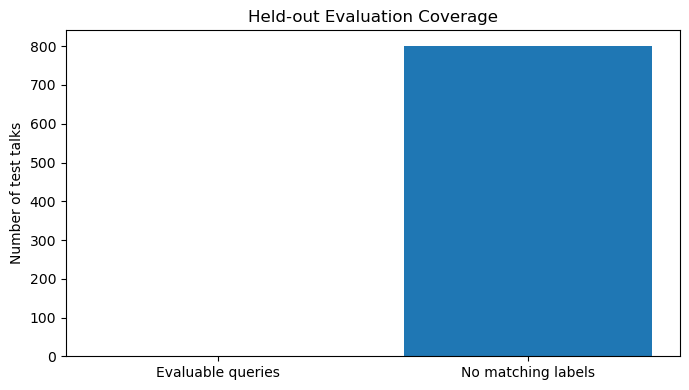

In [11]:
# This cell creates a chart showing the number of held-out queries covered by ground truth.
# Coverage is important because high scores from a small subset may not represent the full test set.

if not coverage.empty:
    covered = int(coverage.loc[0, "queries_with_at_least_one_catalogue_relevant_talk"])
    uncovered = int(coverage.loc[0, "queries_without_matching_relevant_talk"])
    plt.figure(figsize=(7, 4))
    plt.bar(["Evaluable queries", "No matching labels"], [covered, uncovered])
    plt.title("Held-out Evaluation Coverage")
    plt.ylabel("Number of test talks")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "evaluation_coverage.png", dpi=160, bbox_inches="tight")
    plt.show()

## 10. Content-based vs collaborative filtering: trade-off analysis

Content-based filtering is implemented and evaluated because the TED dataset contains talk text and metadata. Collaborative filtering depends on real user–talk interactions (for example, a user ID connected to a rating, click, like or watch event). Talk-level views are aggregate popularity counts and do not identify which user watched which talk.

Therefore:
- **Content-based:** implemented; three TF-IDF variants are compared.
- **Collaborative filtering:** not evaluable with the supplied dataset; no verified user-item interaction matrix can be constructed.
- **Hybrid:** not implemented because a collaborative signal is unavailable.

This is a data limitation, not a failed experiment. Do not state that content-based filtering outperforms collaborative filtering: there is no collaborative baseline score to compare.

In [12]:
# This cell checks whether genuine user identifiers and interaction columns exist.
# It explicitly prevents aggregate talk-level views from being mistaken for user-item interactions.

user_columns = ["user_id", "viewer_id", "member_id"]
interaction_columns = ["rating", "user_rating", "liked", "likes", "clicks", "watch_history", "interaction", "user_feedback"]
found_user_columns = [c for c in user_columns if c in df.columns]
found_interaction_columns = [c for c in interaction_columns if c in df.columns]

collaborative_status = {
    "approach": "Collaborative filtering",
    "status": "Not evaluable" if not (found_user_columns and found_interaction_columns) else "Requires manual validation",
    "user_identifier_columns_found": found_user_columns,
    "interaction_columns_found": found_interaction_columns,
    "reason": (
        "No verified individual user–talk interaction records were found. "
        "Aggregate talk views do not identify user preferences."
        if not (found_user_columns and found_interaction_columns)
        else "Potential columns exist, but their meaning and row-level interaction validity must be verified before training."
    ),
    "hybrid_status": "Not implemented without a validated collaborative signal",
}
print(json.dumps(collaborative_status, indent=2))

{
  "approach": "Collaborative filtering",
  "status": "Not evaluable",
  "user_identifier_columns_found": [],
  "interaction_columns_found": [],
  "reason": "No verified individual user\u2013talk interaction records were found. Aggregate talk views do not identify user preferences.",
  "hybrid_status": "Not implemented without a validated collaborative signal"
}


## 11. Select the final model and document the justification

The default selection rule below uses the **K=10** results and an equal-weight average of Precision, Recall, NDCG and MAP. This is a transparent comparison score for choosing a balanced content-based model; it is not a universal metric. If two models are close, consider interpretability and the intended recommendation experience as well.

The chosen model is selected only if valid evaluation results exist. The output JSON records the scores, selected model and limitations. Review the results before submitting; the report does not claim that the proxy labels are human judgments.

In [13]:
# This cell selects the content-based model with the highest equal-weight mean of four K=10 metrics.
# If metrics are unavailable, it records that a defensible automatic selection could not be made.

selection = {
    "project": "TED Talks Recommendation System - Milestone 3",
    "selection_cutoff_k": 10,
    "selection_method": "Equal-weight mean of Precision@10, Recall@10, NDCG@10 and MAP@10",
    "selected_model": None,
    "selection_score": None,
    "model_scores": [],
    "collaborative_filtering": collaborative_status,
    "ground_truth_note": "TED related-talk references are weak proxy relevance labels, not human-validated judgments.",
}

if not metric_summary.empty:
    k10 = metric_summary[metric_summary["k"] == 10].copy()
    metric_columns = ["precision", "recall", "ndcg", "map"]
    k10["balanced_score"] = k10[metric_columns].mean(axis=1)
    k10 = k10.sort_values("balanced_score", ascending=False)
    selection["model_scores"] = k10[["model", *metric_columns, "balanced_score", "evaluated_queries"]].to_dict("records")
    winner = k10.iloc[0]
    selection["selected_model"] = str(winner["model"])
    selection["selection_score"] = float(winner["balanced_score"])
    selection["justification"] = (
        "Selected because it achieved the highest equal-weight mean across Precision@10, "
        "Recall@10, NDCG@10 and MAP@10 among the evaluated content-based variants. "
        "Interpret the result in light of proxy-label and coverage limitations."
    )
else:
    selection["justification"] = (
        "No model selected automatically because valid proxy relevance labels were unavailable. "
        "Create a manually judged relevance set or obtain verified interaction data before selection."
    )

with open(DOC_DIR / "final_model_selection.json", "w", encoding="utf-8") as file:
    json.dump(selection, file, indent=4, ensure_ascii=False)

print(json.dumps(selection, indent=2, ensure_ascii=False))

{
  "project": "TED Talks Recommendation System - Milestone 3",
  "selection_cutoff_k": 10,
  "selection_method": "Equal-weight mean of Precision@10, Recall@10, NDCG@10 and MAP@10",
  "selected_model": null,
  "selection_score": null,
  "model_scores": [],
  "collaborative_filtering": {
    "approach": "Collaborative filtering",
    "status": "Not evaluable",
    "user_identifier_columns_found": [],
    "interaction_columns_found": [],
    "reason": "No verified individual user–talk interaction records were found. Aggregate talk views do not identify user preferences.",
    "hybrid_status": "Not implemented without a validated collaborative signal"
  },
  "ground_truth_note": "TED related-talk references are weak proxy relevance labels, not human-validated judgments.",
  "justification": "No model selected automatically because valid proxy relevance labels were unavailable. Create a manually judged relevance set or obtain verified interaction data before selection."
}


## 12. Save evaluation reports, comparison tables and recommendation details

In [14]:
# This cell exports all result tables to CSV so they can be used in the written project report.
# Empty evaluation tables are still saved with headers where possible, making the limitation explicit.

coverage.to_csv(REPORT_DIR / "evaluation_coverage.csv", index=False)
metric_summary.to_csv(TABLE_DIR / "model_performance_comparison.csv", index=False)
per_query_results.to_csv(REPORT_DIR / "per_query_evaluation_metrics.csv", index=False)
recommendation_details.to_csv(REPORT_DIR / "top_10_recommendations_for_evaluation_queries.csv", index=False)

# Separate files make the two groups of metrics easy to inspect.
if not metric_summary.empty:
    metric_summary[["model", "k", "precision", "recall", "evaluated_queries"]].to_csv(
        REPORT_DIR / "precision_recall_results.csv", index=False
    )
    metric_summary[["model", "k", "ndcg", "map", "evaluated_queries"]].to_csv(
        REPORT_DIR / "ranking_metrics_results.csv", index=False
    )
else:
    pd.DataFrame(columns=["model", "k", "precision", "recall", "evaluated_queries"]).to_csv(
        REPORT_DIR / "precision_recall_results.csv", index=False
    )
    pd.DataFrame(columns=["model", "k", "ndcg", "map", "evaluated_queries"]).to_csv(
        REPORT_DIR / "ranking_metrics_results.csv", index=False
    )

print("Evaluation reports and tables saved under:", OUTPUT_DIR.resolve())

Evaluation reports and tables saved under: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\milestone3_output


In [15]:
# This cell writes a readable final report using the actual values produced in this notebook.
# If no labels are available, it records the reason rather than filling in invented scores.

report_lines = [
    "# TED Talks Recommendation System — Milestone 3 Evaluation Report",
    "",
    "## Evaluation design",
    f"- Dataset: {dataset_path.name}",
    f"- Training catalogue talks: {len(train_df)}",
    f"- Held-out query talks: {len(test_df)}",
    f"- Train/test split: 80:20; random state {RANDOM_STATE}",
    f"- Relevance source: {related_column or 'Not available'} (weak proxy labels)",
    f"- Evaluable queries: {n_evaluable} of {len(test_df)}",
    "",
    "## Model comparison",
]
if not metric_summary.empty:
    report_lines.append(metric_summary.round(4).to_markdown(index=False))
    report_lines += ["", f"## Final model selection", f"Selected model: **{selection['selected_model']}**", selection["justification"]]
else:
    report_lines += ["Automatic metrics were not calculated because no valid related-talk labels matched the training catalogue."]
    report_lines += ["", "## Final model selection", selection["justification"]]
report_lines += [
    "",
    "## Interpretation and limitations",
    "- Related-talk references are weak proxy labels, not human-validated relevance judgments.",
    "- Results apply only to held-out queries with at least one known relevant talk in the training catalogue.",
    "- Collaborative filtering and hybrid filtering were not evaluated without verified user-item interactions.",
    "- Review sample recommendations manually before making final claims.",
    "",
    "## Reproducibility",
    "The experiment uses the Milestone 2 text preparation, TF-IDF settings, 80:20 split and random state 42.",
]
(DOC_DIR / "final_evaluation_report.md").write_text("\n".join(report_lines), encoding="utf-8")
print("Final evaluation report saved.")

Final evaluation report saved.


## 13. Final verification and submission checklist

In [16]:
# This cell verifies which required Milestone 3 files were generated.
# A file can exist with zero rows when ground-truth labels are unavailable; inspect its contents.

expected_files = [
    REPORT_DIR / "evaluation_coverage.csv",
    REPORT_DIR / "precision_recall_results.csv",
    REPORT_DIR / "ranking_metrics_results.csv",
    REPORT_DIR / "per_query_evaluation_metrics.csv",
    TABLE_DIR / "model_performance_comparison.csv",
    DOC_DIR / "final_model_selection.json",
    DOC_DIR / "final_evaluation_report.md",
]

verification = pd.DataFrame([
    {"file": str(path), "exists": path.exists(), "size_bytes": path.stat().st_size if path.exists() else 0}
    for path in expected_files
])
display(verification)
verification.to_csv(LOG_DIR / "output_verification.csv", index=False)

print("\nMilestone 3 run completed.")
print("Output directory:", OUTPUT_DIR.resolve())

,file,exists,size_bytes
0,milestone3_output\evaluation_reports\evaluatio...,True,252
1,milestone3_output\evaluation_reports\precision...,True,44
2,milestone3_output\evaluation_reports\ranking_m...,True,36
3,milestone3_output\evaluation_reports\per_query...,True,2
4,milestone3_output\tables\model_performance_com...,True,62
5,milestone3_output\documentation\final_model_se...,True,1045
6,milestone3_output\documentation\final_evaluati...,True,1202



Milestone 3 run completed.
Output directory: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\milestone3_output


## Final conclusion — complete after reviewing the actual results

This milestone compares three content-based TED Talk recommendation representations using Precision@K, Recall@K, NDCG@K and MAP@K. The final selection is based on balanced metric performance and interpretability.

**Before submission:**
1. Run every cell from top to bottom without errors.
2. Check the evaluation coverage table and explain how many test queries had valid proxy labels.
3. Inspect the comparison table and plots; do not report placeholder or empty metrics as scores.
4. Manually review a sample of recommendations for relevance and diversity.
5. Explain that related-talk references are proxy labels, not human relevance judgments.
6. Explain why collaborative filtering and hybrid filtering could not be evaluated without user-interaction data.
7. Include the generated `milestone3_output/` folder with this notebook.

**Academic integrity note:** The notebook calculates results from the supplied dataset when run locally. No scores are pre-filled or fabricated. The final conclusions must be based on the actual output of your run.